In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Dataset_Newspaper.xlsx to Dataset_Newspaper (2).xlsx


In [ ]:
df = pd.read_excel("Dataset_Newspaper (2).xlsx")
df.head()

,Date,Newspaper,Language,Category,Headline,Is_Advertisement
0,2026-03-22,Lokmat,Marathi,Advertisement,भारतीय सैन्यदलात राष्ट्रसेवेसह घडवा अभिमानास्प...,Yes
1,2026-03-22,Lokmat,Marathi,Politics,रॉय-दळवी भेट,No
2,2026-03-22,Lokmat,Marathi,Health,रुग्णसंख्या पोहोचली १५६ वर,No
3,2026-03-22,Lokmat,Marathi,Business,कॅश डिपॉझिट मशिनमध्ये जमा केल्या बोगस नोटा,No
4,2026-03-22,Lokmat,Marathi,Politics,५०% वीजवाहिन्या भूमिगत केबलमध्ये रूपांतरित: वी...,No


In [ ]:
df.shape

(500, 6)

In [ ]:
df["Headline_Length"] = df["Headline"].str.len()
df["Headline_Length"]

,Headline_Length
0,54
1,13
2,27
3,43
4,66
...,...
495,34
496,28
497,24
498,52


In [ ]:
df.groupby("Language")["Headline_Length"].mean().sort_values(ascending=False)

,Headline_Length
Language,
Malayalam,46.923077
English,46.650000
Marathi,37.206731
Kannada,32.656250


In [ ]:
idx = df.groupby("Language")["Headline_Length"].idxmin()
print(df.loc[idx, ["Language", "Headline", "Headline_Length"]])

      Language              Headline  Headline_Length
348    English  Sindhu enters 2nd rd               20
276    Kannada            ರೈತರ ವಿರೋಧ               10
419  Malayalam     ചതുരംഗ പടയൊരുക്കം               17
475    Marathi            आरजी कुठे?               10


In [ ]:
idx = df.groupby("Language")["Headline_Length"].idxmax()
print(df.loc[idx, ["Language", "Headline", "Headline_Length"]])

      Language                                           Headline  \
352    English  VCK, DMK members clash at Kunnam bus stand; po...   
316    Kannada  Modern Education combined with the learning of...   
427  Malayalam  കിടപ്പുമുറിയിൽ കട്ടിലിനിടിയിൽ പ്രത്യേക അറയുണ്ട...   
222    Marathi  अंत्यसंस्कार सुरु असतानाच एका न्यायाधीशाने केल...   

     Headline_Length  
352               77  
316               86  
427              104  
222               81  


In [ ]:
df.groupby("Language")["Headline_Length"].std().sort_values(ascending=False)

,Headline_Length
Language,
Malayalam,18.844926
Marathi,13.395527
English,12.859612
Kannada,12.133454


In [ ]:
print(pd.crosstab(df["Language"], df["Category"]))

Category   Advertisement  Business  Education  Entertainment  Health  \
Language                                                               
English               10         8          2              3       7   
Kannada                4        15         10              6       4   
Malayalam              2         6          1              0       2   
Marathi                8        22         25              3       9   

Category   International  Local  Politics  Sports  Technology  
Language                                                       
English                6     16        21       4           3  
Kannada                8     69        32      10           2  
Malayalam              6      4        17      14           0  
Marathi                6     74        40      18           3  


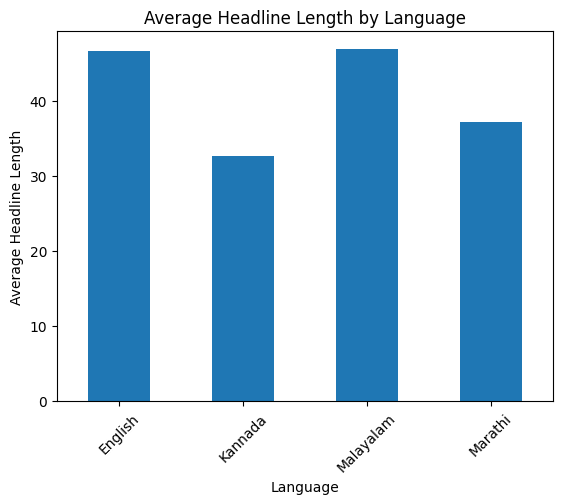

In [ ]:
avg_length = df.groupby("Language")["Headline_Length"].mean()

avg_length.plot(kind="bar")

plt.title("Average Headline Length by Language")
plt.xlabel("Language")
plt.ylabel("Average Headline Length")
plt.xticks(rotation=45)
plt.show()